# 04 · Como BH se compara em qualidade de vida? Dimensões, componentes e inclusão social

Primeira parte da Pergunta 2: onde BH fica acima ou abaixo da mediana da RMBH em cada dimensão e componente do IPS, e o que explica o resultado em Inclusão Social.

> Parte 4 de 6 do projeto *BH e Região sob a perspectiva dos dados*. Veja o [README](../README.md) para a visão geral.

In [1]:
# Configuração: funciona no computador (a partir da pasta notebooks/) e no Google Colab
import os
import subprocess
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo = Path('/content/ips-bh-rmbh')
    if not repo.exists():
        subprocess.run(['git', 'clone', '-q', 'https://github.com/millebns/ips-bh-rmbh.git', str(repo)], check=True)
    os.chdir(repo / 'notebooks')

sys.path.insert(0, str(Path.cwd().parent / 'src'))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from ips_rmbh.config import DIMENSOES as dimensoes, COMPONENTES as componentes

from functools import partial

from ips_rmbh import analise
from ips_rmbh.config import BH, COR_BH, COR_OUTROS, COR_DESTAQUE, PASTA_FIGURAS
from ips_rmbh.dados import carregar_rmbh

df_rmbh = carregar_rmbh()

# Atalhos que comparam BH com os demais municípios da RMBH
posicao_bh = partial(analise.posicao, df_rmbh)
valor_bh = partial(analise.valor, df_rmbh)
print(df_rmbh.shape)
perfil = partial(analise.perfil, df_rmbh)

(34, 78)


## Dimensões e componentes do IPS

In [3]:
# A função perfil() está em src/ips_rmbh/analise.py
perfil(dimensoes)

,item,BH,mediana_RMBH,diferenca,posicao_BH
0,Oportunidades,54.94,43.46,11.47,3
1,Fundamentos do Bem-estar,74.87,71.02,3.85,2
2,Necessidades Humanas Básicas,79.15,76.24,2.91,10


In [4]:
perfil_comp = perfil(componentes)
perfil_comp

,item,BH,mediana_RMBH,diferenca,posicao_BH
0,Acesso à Educação Superior,72.45,34.79,37.66,1
1,Direitos Individuais,58.70,26.26,32.44,1
2,Água e Saneamento,88.90,79.68,9.23,1
3,Acesso à Informação e Comunicação,93.00,84.25,8.75,2
4,Qualidade do Meio Ambiente,65.32,62.06,3.26,10
5,Saúde e Bem-estar,65.71,62.56,3.14,6
6,Segurança Pessoal,67.41,67.00,0.41,15
7,Acesso ao Conhecimento Básico,75.45,75.41,0.04,17
8,Nutrição e Cuidados Médicos Básicos,74.62,75.28,-0.66,20
9,Liberdades Individuais e de Escolha,56.12,57.92,-1.80,22


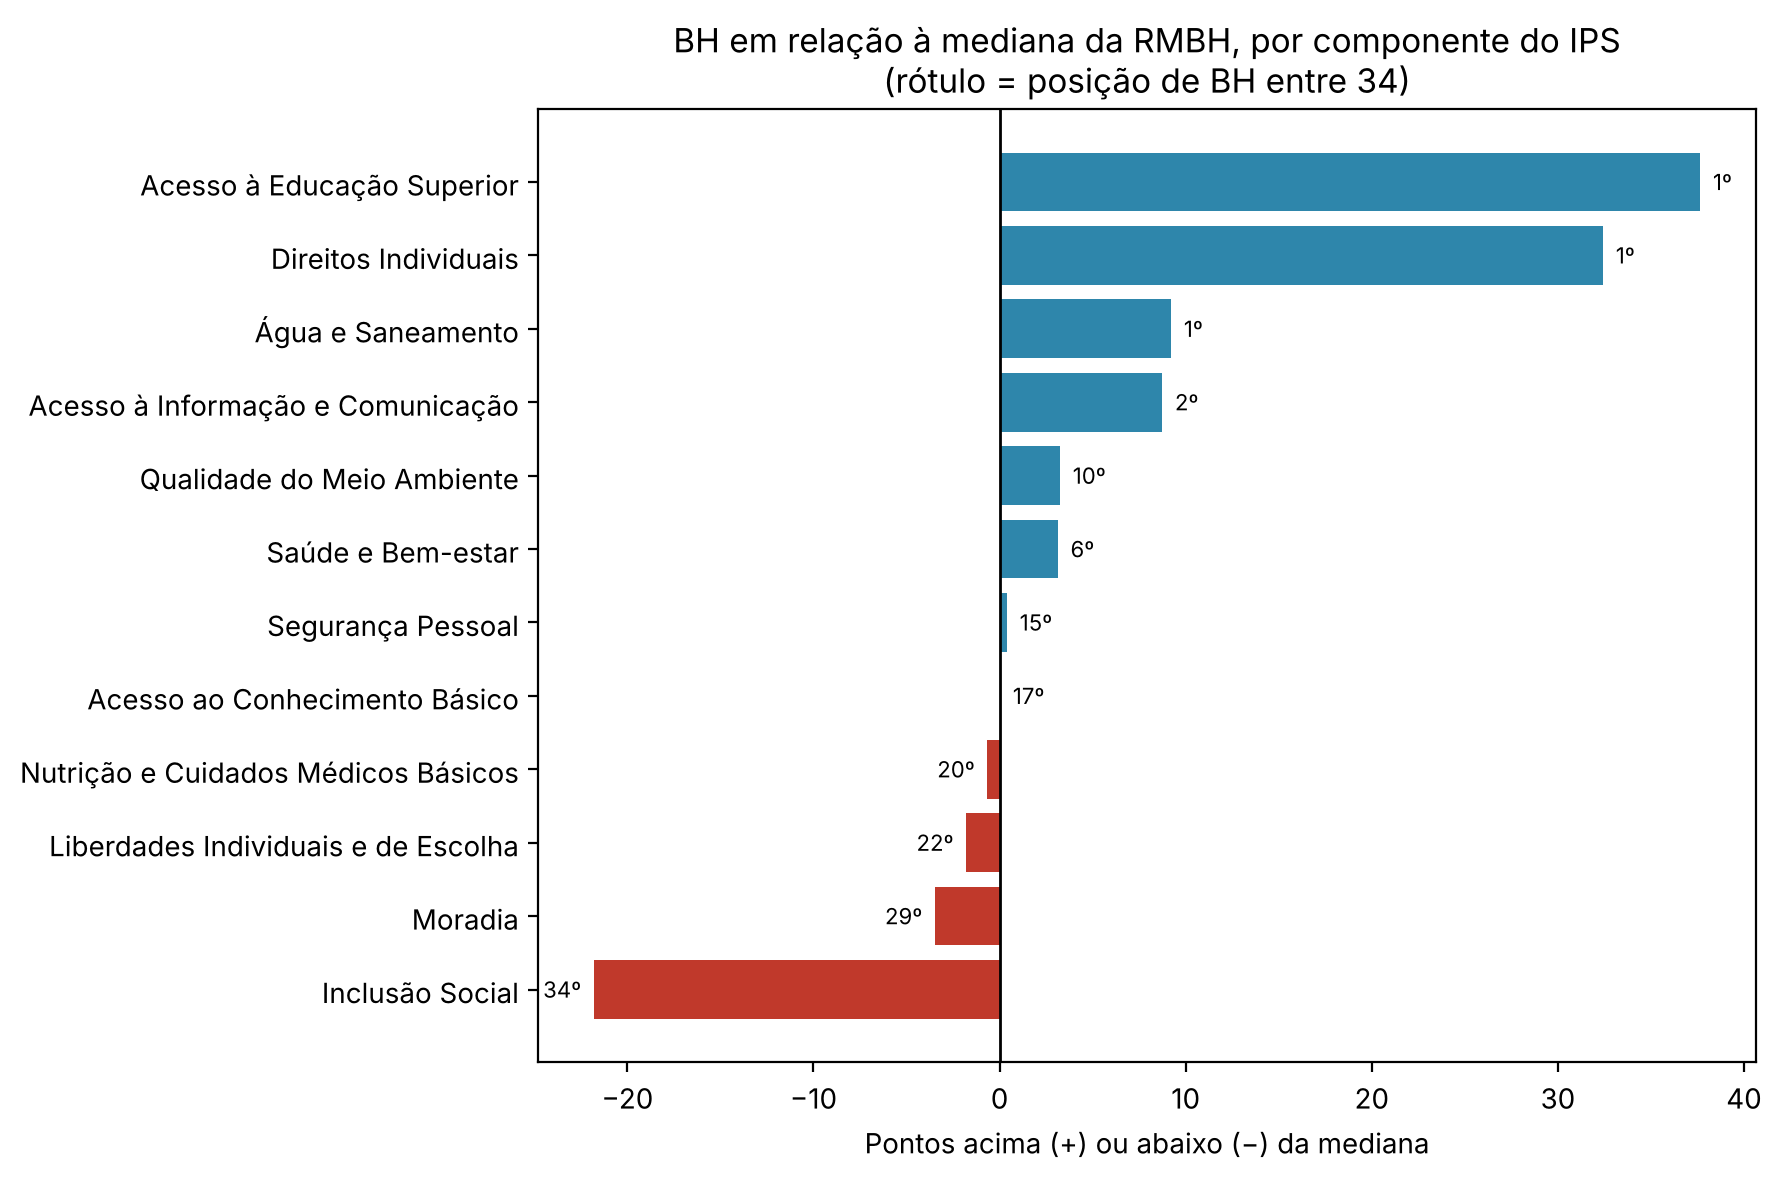

In [5]:
graf = perfil_comp.sort_values('diferenca')

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(graf['item'], graf['diferenca'],
        color=[COR_BH if d < 0 else '#2E86AB' for d in graf['diferenca']])
ax.axvline(0, c='black', lw=1)
for y, (d, p) in enumerate(zip(graf['diferenca'], graf['posicao_BH'])):
    ax.text(d, y, f'  {p}º  ', va='center', ha='left' if d >= 0 else 'right', fontsize=8)
ax.set_title('BH em relação à mediana da RMBH, por componente do IPS\n(rótulo = posição de BH entre 34)')
ax.set_xlabel('Pontos acima (+) ou abaixo (−) da mediana')
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / '02_componentes_bh_vs_mediana.png', dpi=150, bbox_inches='tight')
plt.show()

BH fica acima da mediana nas três dimensões, com maior vantagem em Oportunidades (3ª posição). Nos componentes, o perfil é desigual: BH é 1ª em Acesso à Educação Superior, Direitos Individuais e Água e Saneamento, mas é a última (34ª) em Inclusão Social, 21,8 pontos abaixo da mediana, e a 29ª em Moradia.

## O que explica o resultado em Inclusão Social?

In [6]:
# True = maior é melhor; False = menor é melhor
inclusao = {
    'Famílias em Situação de Rua': False,
    'Violência Contra Mulheres': False,
    'Violência Contra Negros': False,
    'Violência Contra Indígenas': False,
    'Paridade de Gênero na Câmara Municipal': True,
    'Paridade de Negros na Câmara Municipal': True,
}

pd.DataFrame([{
    'indicador': c,
    'BH': round(valor_bh(c), 2),
    'mediana_RMBH': round(df_rmbh[c].median(), 2),
    'posicao_BH': posicao_bh(c, maior_melhor),
} for c, maior_melhor in inclusao.items()])

,indicador,BH,mediana_RMBH,posicao_BH
0,Famílias em Situação de Rua,432.01,26.05,34
1,Violência Contra Mulheres,281.02,233.93,21
2,Violência Contra Negros,186.69,102.70,24
3,Violência Contra Indígenas,78.04,67.34,11
4,Paridade de Gênero na Câmara Municipal,0.59,0.29,4
5,Paridade de Negros na Câmara Municipal,0.74,0.74,18


O indicador que mais pesa é Famílias em Situação de Rua: 432 em BH, contra uma mediana regional de 26 (cerca de 17 vezes mais).

Nas violências contra pessoas negras e contra mulheres, BH também fica abaixo da mediana.

Por outro lado, BH é a 4ª em paridade de gênero na Câmara Municipal. Observação: 16 municípios da RMBH não têm dado de Violência Contra Indígenas, então a posição de BH nesse indicador é entre os 18 que têm.

**Próximo notebook:** [05 · IPS x PIB per capita](05_ips_x_pib.ipynb)